# Prédire le prix d'un appartement

Deuxième notebook. On part des données nettoyées dans `01_exploration.ipynb` et on cherche à prédire le **prix de vente d'un appartement** à partir de ses caractéristiques : surface, nombre de pièces, localisation et date de la vente.

Je me limite aux appartements (87 % des ventes). Les maisons sont peu nombreuses à Paris et ont une logique de prix différente (terrain, etc.), elles mériteraient un modèle à part.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsRegressor

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

In [2]:
df = pd.read_parquet("../data/processed/dvf_clean.parquet")
df = df[df["type_local"] == "Appartement"].copy()
print(len(df), "ventes d'appartements")

321366 ventes d'appartements


## Variables

À partir des colonnes disponibles, je construis :
- `surface` et `pieces` : directement dans les données
- `latitude`, `longitude` : la position exacte du bien
- `dist_centre` : distance en km à Notre-Dame, qui résume la position en un seul chiffre
- `t` : date de la vente en années depuis janvier 2021, pour capter l'évolution du marché
- `code_commune` : la commune ou l'arrondissement, en variable catégorielle

La cible est le **logarithme du prix**. Les prix vont de quelques dizaines de milliers d'euros à plusieurs millions : en passant au log, une erreur de 10 % pèse autant sur un studio que sur un grand appartement.

In [3]:
NOTRE_DAME = (48.8530, 2.3499)

df["surface"] = df["surface_reelle_bati"]
df["pieces"] = df["nombre_pieces_principales"]
df["t"] = (df["date_mutation"] - pd.Timestamp("2021-01-01")).dt.days / 365.25
# 1 degré de latitude ≈ 111 km, 1 degré de longitude ≈ 73 km à la latitude de Paris
df["dist_centre"] = np.sqrt(((df["latitude"] - NOTRE_DAME[0]) * 111) ** 2
                            + ((df["longitude"] - NOTRE_DAME[1]) * 73) ** 2)
df["code_commune"] = df["code_commune"].astype("category")

FEATURES = ["surface", "pieces", "latitude", "longitude", "dist_centre", "t", "code_commune"]
X = df[FEATURES]
y = np.log(df["valeur_fonciere"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"train : {len(X_train):,}  |  test : {len(X_test):,}")

train : 257,092  |  test : 64,274


## Le prix du quartier

La localisation est de loin ce qui compte le plus dans l'immobilier. Les modèles à base d'arbres peuvent l'apprendre à partir de la latitude et de la longitude, mais une régression linéaire en est incapable.

J'ajoute donc une variable `prix_quartier` : le prix au m² moyen (en log) des 30 ventes les plus proches géographiquement.

**Attention à la fuite de données.** Si je calcule cette variable avec toutes les ventes, le prix du bien lui-même entre dans le calcul de sa propre variable, et le modèle triche. Je la calcule donc :
- sur le train, en validation croisée (chaque vente reçoit une valeur calculée sans elle) ;
- sur le test, uniquement à partir des ventes du train.

In [4]:
COORDS = ["latitude", "longitude"]
log_prix_m2_train = np.log(df.loc[X_train.index, "prix_m2"])

knn = KNeighborsRegressor(n_neighbors=30)
X_train = X_train.assign(prix_quartier=cross_val_predict(knn, X_train[COORDS], log_prix_m2_train, cv=5))
knn.fit(X_train[COORDS], log_prix_m2_train)
X_test = X_test.assign(prix_quartier=knn.predict(X_test[COORDS]))

## Évaluation

Trois mesures, toutes calculées en euros (après être revenu du log) :
- **MAE** : erreur absolue moyenne, en euros
- **erreur médiane en %** : la moitié des biens sont estimés avec une erreur inférieure à ce chiffre. C'est la mesure la plus parlante, et la moins sensible aux quelques ventes atypiques
- **R²** : part de la variance des prix expliquée par le modèle

In [5]:
resultats = {}

def evaluer(nom, pred_log):
    reel, pred = np.exp(y_test), np.exp(pred_log)
    resultats[nom] = {
        "MAE (€)": mean_absolute_error(reel, pred),
        "erreur médiane (%)": 100 * np.median(np.abs(pred - reel) / reel),
        "R²": r2_score(reel, pred),
    }
    return pd.Series(resultats[nom]).round(3)

## 1. Point de départ : la méthode « agent immobilier »

Avant tout modèle, une règle simple : prix au m² médian de l'arrondissement ou de la commune, multiplié par la surface. Tout modèle doit faire mieux que ça pour être utile.

In [6]:
prix_m2_commune = df.loc[X_train.index].groupby("code_commune", observed=True)["prix_m2"].median()
pred_naive = X_test["code_commune"].map(prix_m2_commune).astype(float) * X_test["surface"]
evaluer("Prix m² médian de la commune × surface", np.log(pred_naive))

MAE (€)               84242.837
erreur médiane (%)       14.072
R²                        0.826
dtype: float64

## 2. Régression linéaire

In [7]:
def lineaire(X, avec_quartier):
    cols = {"log_surface": np.log(X["surface"]), "pieces": X["pieces"], "t": X["t"], "dist_centre": X["dist_centre"]}
    if avec_quartier:
        cols["prix_quartier"] = X["prix_quartier"]
    return pd.DataFrame(cols)

for avec_quartier, nom in [(False, "Régression linéaire"), (True, "Régression linéaire + prix du quartier")]:
    lr = LinearRegression().fit(lineaire(X_train, avec_quartier), y_train)
    print(nom)
    print(evaluer(nom, lr.predict(lineaire(X_test, avec_quartier))), "\n")

Régression linéaire
MAE (€)               173520.037
erreur médiane (%)        32.202
R²                         0.450
dtype: float64 

Régression linéaire + prix du quartier
MAE (€)               85145.093
erreur médiane (%)       12.988
R²                        0.795
dtype: float64 



Sans information fine sur la localisation, la régression linéaire est mauvaise : la distance au centre ne suffit pas (un appartement à 3 km de Notre-Dame peut être dans le 16e ou dans le 19e). Avec le prix du quartier, elle devient correcte.

## 3. Random Forest

In [8]:
NUM = ["surface", "pieces", "latitude", "longitude", "dist_centre", "t", "prix_quartier"]
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=0)
rf.fit(X_train[NUM], y_train)
evaluer("Random Forest", rf.predict(X_test[NUM]))

MAE (€)               80833.034
erreur médiane (%)       12.392
R²                        0.816
dtype: float64

## 4. Gradient boosting

J'utilise `HistGradientBoostingRegressor` de scikit-learn, qui fonctionne comme LightGBM : rapide sur des centaines de milliers de lignes et capable de gérer directement la variable catégorielle `code_commune`.

In [9]:
gb = HistGradientBoostingRegressor(max_iter=1500, learning_rate=0.08, max_leaf_nodes=127,
                                   categorical_features="from_dtype", random_state=0)
gb.fit(X_train, y_train)
evaluer("Gradient boosting", gb.predict(X_test))

MAE (€)               80603.318
erreur médiane (%)       12.200
R²                        0.806
dtype: float64

## Comparaison

In [10]:
comparaison = pd.DataFrame(resultats).T.sort_values("erreur médiane (%)")
comparaison.style.format({"MAE (€)": "{:,.0f}", "erreur médiane (%)": "{:.1f}", "R²": "{:.3f}"})

,MAE (€),erreur médiane (%),R²
Gradient boosting,"80,603",12.2,0.806
Random Forest,"80,833",12.4,0.816
Régression linéaire + prix du quartier,"85,145",13.0,0.795
Prix m² médian de la commune × surface,"84,243",14.1,0.826
Régression linéaire,"173,520",32.2,0.450


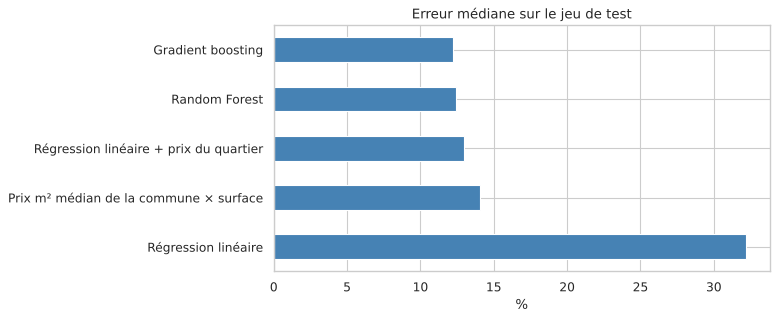

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
comparaison["erreur médiane (%)"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set(title="Erreur médiane sur le jeu de test", xlabel="%", ylabel="")
plt.savefig(FIG_DIR / "comparaison_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

## Qu'est-ce qui compte pour le modèle ?

Importance par permutation : on mélange une variable au hasard et on mesure à quel point le modèle se dégrade. Plus il se dégrade, plus la variable est importante. Calculé sur 10 000 ventes du test pour que ça reste rapide.

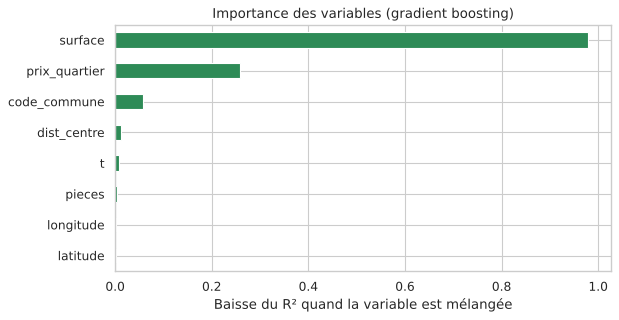

In [12]:
echantillon = X_test.sample(10_000, random_state=0)
imp = permutation_importance(gb, echantillon, y_test.loc[echantillon.index], n_repeats=5, random_state=0)
importances = pd.Series(imp.importances_mean, index=echantillon.columns).sort_values()

ax = importances.plot.barh(figsize=(8, 4), color="seagreen")
ax.set(title="Importance des variables (gradient boosting)", xlabel="Baisse du R² quand la variable est mélangée")
plt.savefig(FIG_DIR / "importance_variables.png", dpi=150, bbox_inches="tight")
plt.show()

La surface arrive largement en tête, puis la localisation via `prix_quartier` et `code_commune`. La latitude et la longitude semblent inutiles, mais c'est parce que leur information est déjà contenue dans `prix_quartier` : quand on mélange l'une, le modèle se rabat sur l'autre. Le nombre de pièces n'apporte presque rien une fois la surface connue.

## Où le modèle se trompe-t-il ?

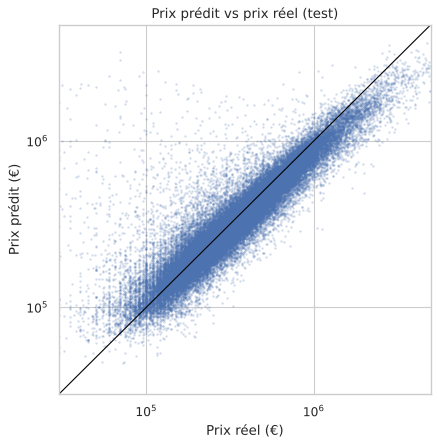

In [13]:
test = df.loc[X_test.index, ["valeur_fonciere", "surface", "code_departement"]].copy()
test["prediction"] = np.exp(gb.predict(X_test))
test["erreur_pct"] = 100 * (test["prediction"] - test["valeur_fonciere"]).abs() / test["valeur_fonciere"]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test["valeur_fonciere"], test["prediction"], s=2, alpha=0.15)
lims = [3e4, 5e6]
ax.plot(lims, lims, color="black", lw=1)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="Prix réel (€)", ylabel="Prix prédit (€)", title="Prix prédit vs prix réel (test)")
plt.savefig(FIG_DIR / "predit_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()

La plupart des points suivent la diagonale. On voit en revanche une bande verticale de ventes autour de 100 000 € ou moins que le modèle estime bien plus cher : ce sont probablement des ventes atypiques (viager, vente entre membres d'une même famille, bien à rénover entièrement), que les données ne permettent pas d'identifier.

In [14]:
noms = {"75": "Paris", "92": "Hauts-de-Seine", "93": "Seine-Saint-Denis", "94": "Val-de-Marne"}
print("Erreur médiane par département (%)")
print(test.groupby("code_departement")["erreur_pct"].median().rename(index=noms).round(1).to_string())

test["tranche_surface"] = pd.cut(test["surface"], [0, 25, 45, 70, 100, 500],
                                 labels=["< 25 m²", "25-45 m²", "45-70 m²", "70-100 m²", "> 100 m²"])
print("\nErreur médiane par surface (%)")
print(test.groupby("tranche_surface", observed=True)["erreur_pct"].median().round(1).to_string())

print(f"\nPart des biens estimés à moins de 20 % près : {(test['erreur_pct'] < 20).mean():.0%}")

Erreur médiane par département (%)
code_departement
Paris                14.4
Hauts-de-Seine       10.6
Seine-Saint-Denis    11.5
Val-de-Marne         10.3

Erreur médiane par surface (%)
tranche_surface
< 25 m²      15.0
25-45 m²     12.3
45-70 m²     10.9
70-100 m²    11.4
> 100 m²     16.6

Part des biens estimés à moins de 20 % près : 72%


## Sauvegarde

Le modèle et le KNN du prix du quartier sont sauvegardés pour l'application d'estimation.

In [15]:
joblib.dump({"modele": gb, "knn_quartier": knn, "features": list(X_train.columns)},
            MODEL_DIR / "modele_prix.joblib")

['../models/modele_prix.joblib']

## Ce qu'on retient

| Méthode | Erreur médiane | MAE | R² |
|---|---|---|---|
| Prix m² médian de la commune × surface | 14,1 % | 84 243 € | 0,826 |
| Régression linéaire | 32,2 % | 173 520 € | 0,450 |
| Régression linéaire + prix du quartier | 13,0 % | 85 145 € | 0,795 |
| Random Forest | 12,4 % | 80 833 € | 0,816 |
| Gradient boosting | **12,2 %** | **80 603 €** | 0,806 |

- **La règle simple est déjà très bonne.** Prix au m² de la commune × surface donne 14,1 % d'erreur médiane. Le gradient boosting descend à 12,2 %, soit 2 points de mieux et environ 3 600 € d'erreur moyenne en moins. C'est un vrai gain, mais pas une révolution.
- **La variable `prix_quartier` fait l'essentiel du travail.** Avec elle, une simple régression linéaire passe de 32 % à 13 % d'erreur, presque au niveau des modèles plus complexes.
- **Le R² en euros ne départage pas les modèles.** Il est dominé par les biens les plus chers, alors que les modèles sont entraînés sur le log du prix pour être bons en pourcentage sur tous les biens. C'est pour ça que je regarde surtout l'erreur médiane.
- **Paris est plus difficile à prédire** (14,4 % d'erreur médiane contre 10 à 12 % en petite couronne), tout comme les très petites et très grandes surfaces. 72 % des biens sont estimés à moins de 20 % près.

**Limites :**
- On ne connaît ni l'étage, ni l'état du bien, ni la présence d'un balcon ou d'un ascenseur. Une partie de l'erreur restante est donc impossible à réduire avec ces données.
- Les ventes atypiques (viager, ventes familiales) restent dans les données et pèsent sur l'erreur.
- Le découpage train/test est aléatoire. Pour estimer le prix d'une vente future, il faudrait valider sur une période postérieure à l'entraînement.